# Lab RAG para Designing Machine Learning Systems

Este notebook inicia a linha de base (baseline RAG) e a variante adaptive RAG para comparar:
- qualidade das respostas
- latência
- custo de chamadas ao LLM
- variação entre execuções

A estrutura foi desenhada para usar o PDF local do livro e as 20 perguntas em `questions.json`.


In [1]:
!pip install -q pypdf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 402.7/402.7 kB 15.6 MB/s eta 0:00:00


In [40]:
import subprocess
gpu_info = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total',
                           '--format=csv,noheader'], capture_output=True, text=True).stdout.strip()
print(gpu_info)

NVIDIA RTX PRO 6000 Blackwell Server Edition, 97887 MiB


### Instalação e Configuração do Ollama no Google Colab

Como o Ollama não vem pré-instalado por padrão na máquina virtual do Colab, precisamos:
1. Baixar e instalar o executável do Ollama.
2. Iniciar o servidor em segundo plano (`ollama serve`).
3. Baixar (pull) o modelo de linguagem configurado (`qwen2.5:7b`).

In [2]:
%%bash
# Instalar a dependência zstd necessária para a extração do instalador do Ollama
sudo apt-get update && sudo apt-get install -y zstd

# 1. Instalar o Ollama usando o instalador oficial de forma silenciosa
curl -fsSL https://ollama.com/install.sh | sh

Hit:1 https://cli.github.com/packages stable InRelease
Get:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  Packages [1,919 kB]
Get:4 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:5 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Hit:6 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:7 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Get:8 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble/main amd64 Packages [52.1 kB]
Get:10 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:11 http://security.ubuntu.com/ubuntu noble-security/multiverse amd64 Packages [55.6 kB]
Get:12 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:13 http://securi

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.

In [3]:
import subprocess
import time
import os
import requests

print("Limpando instâncias existentes do Ollama...")
subprocess.run(["pkill", "ollama"])
time.sleep(2)

print("Iniciando o servidor Ollama forçando escuta em 127.0.0.1:11434...")
# Definir explicitamente o host para evitar falhas de resolução de nome/interface local
env = os.environ.copy()
env["OLLAMA_HOST"] = "127.0.0.1:11434"

process = subprocess.Popen(
    ["ollama", "serve"],
    env=env,
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

# Esperar o processo se consolidar e verificar ping
for i in range(25):
    try:
        response = requests.get('http://127.0.0.1:11434/')
        if response.status_code == 200:
            print("✅ Servidor Ollama operando e respondendo em http://127.0.0.1:11434!")
            break
    except requests.exceptions.ConnectionError:
        time.sleep(1)
else:
    print("❌ Falha crítica ao iniciar o Ollama no host local.")

Limpando instâncias existentes do Ollama...
Iniciando o servidor Ollama forçando escuta em 127.0.0.1:11434...
✅ Servidor Ollama operando e respondendo em http://127.0.0.1:11434!


In [4]:
# 3. Fazer o download do modelo configurado (padrão: qwen2.5:7b)
try:
    model_name = config.get('generator_model', 'qwen2.5:7b')
except NameError:
    model_name = 'qwen2.5:7b'

print(f"Fazendo o download do modelo '{model_name}' (isso pode levar alguns minutos)... ")

!ollama pull {model_name}

print(f"\n✅ Modelo '{model_name}' pronto para uso!")

Fazendo o download do modelo 'qwen2.5:7b' (isso pode levar alguns minutos)... 


✅ Modelo 'qwen2.5:7b' pronto para uso!


In [5]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import requests
from pypdf import PdfReader
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# --- ROOT: funciona no servidor local e no Colab ---
def find_root():
    candidates = [Path.cwd(), Path('/content')]
    # cobre projeto extraído em subpasta (ex.: /content/rag-dmls-lab/)
    candidates.extend(p.parent for p in Path('/content').glob('*/questions.json'))
    for c in candidates:
        if (c / 'questions.json').exists() and ((c / 'experiment.json').exists() or (c / 'experiment.json').exists()):
            return c
    return Path('/content')  # destino padrão do upload no Colab

ROOT = find_root()

# Procura o experiment.json na raiz ou na pasta configs
if (ROOT / 'experiment.json').exists():
    CONFIG_PATH = ROOT / 'experiment.json'
else:
    CONFIG_PATH = ROOT / 'experiment.json'

QUESTIONS_PATH = ROOT / 'questions.json'

def load_json(path):
    if not path.exists():
        raise FileNotFoundError(
            f'Arquivo não encontrado: {path}\n'
            'No Colab: suba questions.json e experiment.json diretamente na raiz do projeto.'
        )
    with open(path, 'r', encoding='utf-8') as fh:
        return json.load(fh)

config = load_json(CONFIG_PATH)
questions = load_json(QUESTIONS_PATH)

# validação mínima da estrutura das perguntas
assert questions.get('questions'), "questions.json não contém a lista 'questions'."
required_q = {'id', 'question', 'category', 'difficulty'}
missing = [k for k in required_q if k not in questions['questions'][0]]
assert not missing, f"Campos ausentes nas perguntas: {missing}"

first = questions['questions'][0]
if not any(k in first for k in ('answer', 'answer_key', 'expected_answer')):
    print("⚠️ Sem answer key detectada — necessária para calcular acurácia depois.")

print(f"Projeto: {config.get('project_name', 'rag-dmls-lab')}")
print(f"Perguntas carregadas: {len(questions['questions'])}")
print(f"Tema: {config.get('topic', 'Designing Machine Learning Systems')}")
print(f"ROOT: {ROOT}")

⚠️ Sem answer key detectada — necessária para calcular acurácia depois.
Projeto: rag-dmls-lab
Perguntas carregadas: 20
Tema: Designing Machine Learning Systems
ROOT: /content


In [6]:
from pathlib import Path

def find_pdf_path(root=None):
    """Localiza o PDF do corpus em ordem de prioridade.

    Ordem de busca:
      1. Caminho explícito em configs/experiment.json (chave 'corpus_pdf_path')
      2. Pastas do projeto (corpus/documentos, corpus) — layout do servidor
      3. Raiz do ambiente (/content no Colab) — destino do files.upload()
      4. /kaggle/input — datasets do Kaggle, se um dia migrar
    """
    root = Path(root or ROOT)

    # 1) override explícito via config (opcional, tem prioridade máxima)
    explicit = config.get('corpus_pdf_path')
    if explicit and Path(explicit).is_file():
        return Path(explicit)

    candidates = [
        root / 'corpus' / 'documentos',
        root / 'corpus',
        root,
        Path('/content'),
        Path('/kaggle/input'),
    ]
    searched = []
    for folder in candidates:
        if not folder.exists():
            continue
        searched.append(str(folder))
        matches = sorted(
            p for p in folder.rglob('*.pdf')
            if p.suffix.lower() == '.pdf'
            and not p.name.startswith(('.', '~', '$'))
        )
        if matches:
            if len(matches) > 1:
                print(f'⚠️ Vários PDFs encontrados em {folder}; usando o primeiro:')
                for m in matches:
                    print(f'   - {m}')
            return matches[0]

    raise FileNotFoundError(
        'PDF do livro não encontrado. Pastas verificadas: ' + '; '.join(searched)
        + '. Opções: (a) coloque o PDF em corpus/documentos/, '
        '(b) faça upload direto no Colab, ou '
        "(c) defina 'corpus_pdf_path' no configs/experiment.json."
    )

pdf_path = find_pdf_path(ROOT)
print(f'Arquivo PDF localizado: {pdf_path}')

Arquivo PDF localizado: /content/designing-machine-learning-systems-2022.pdf


In [7]:
def read_pdf_pages(pdf_path):
    """Lê todas as páginas do PDF e retorna uma lista de strings."""
    reader = PdfReader(pdf_path)
    pages = []
    for page in reader.pages:
        text = page.extract_text()
        if text:
            pages.append(text)
    return pages

def chunk_text(text, chunk_size=800, overlap=120):
    """Divide o texto em blocos (chunks) de tamanho fixo com sobreposição."""
    chunks = []
    start = 0
    while start < len(text):
        end = start + chunk_size
        chunks.append(text[start:end])
        start += chunk_size - overlap
    return chunks

print("Funções 'read_pdf_pages' e 'chunk_text' definidas com sucesso!")

Funções 'read_pdf_pages' e 'chunk_text' definidas com sucesso!


In [8]:
# Extraindo o texto de todas as páginas do PDF
print("Extraindo texto do PDF...")
pages_text = read_pdf_pages(pdf_path)
full_text = '\n\n'.join(pages_text)

# Obtendo as configurações de tamanho do chunk e overlap
chunk_size = config.get('chunk_size_chars', 800)
overlap = config.get('chunk_overlap_chars', 120)

# Gerando os chunks utilizando a função definida
chunks = chunk_text(full_text, chunk_size=chunk_size, overlap=overlap)

print(f"✓ Extração concluída!")
print(f"Total de páginas processadas: {len(pages_text)}")
print(f"Total de chunks gerados: {len(chunks)}")
if chunks:
    print(f"\nExemplo do primeiro chunk (tamanho {len(chunks[0])} caracteres):")
    print("-" * 50)
    print(chunks[0][:400] + "...")
    print("-" * 50)

Extraindo texto do PDF...
✓ Extração concluída!
Total de páginas processadas: 313
Total de chunks gerados: 719

Exemplo do primeiro chunk (tamanho 800 caracteres):
--------------------------------------------------
Designing Machine Learning
Systems
An Iterative Process for Production-Ready
Applications
With Early Release ebooks, you get books in their earliest form—the
author’s raw and unedited content as they write—so you can take
advantage of these technologies long before the official release of these
titles.
Chip Huyen

Designing Machine Learning Systems
by Chip Huyen
Copyright © 2022 Huyen Thi Khanh Ng...
--------------------------------------------------


In [9]:
def build_index(chunks):
    vectorizer = TfidfVectorizer(stop_words='english', ngram_range=(1, 2))
    matrix = vectorizer.fit_transform(chunks)
    return vectorizer, matrix

# Construindo o índice TF-IDF com os chunks gerados
print("Indexando os chunks com TF-IDF...")
vectorizer, matrix = build_index(chunks)

print("✓ Indexação concluída!")
print(f"Dimensões da matriz TF-IDF (Nº Chunks, Nº Vocabulário): {matrix.shape}")

Indexando os chunks com TF-IDF...
✓ Indexação concluída!
Dimensões da matriz TF-IDF (Nº Chunks, Nº Vocabulário): (719, 37795)


In [10]:
def build_index(chunks):
    vectorizer = TfidfVectorizer(stop_words='english', ngram_range=(1, 2))
    matrix = vectorizer.fit_transform(chunks)
    return vectorizer, matrix

def expand_query(query):
    expansions = {
        'business value': 'business objective success metric problem framing use case',
        'clear definition of the problem': 'problem framing task definition objective success criteria',
        'data-centric approach': 'data-centric AI data quality labels dataset improvement',
        'model-centric approach': 'model-centric AI algorithm architecture model improvement',
        'real-world performance': 'production performance deployment distribution shift noisy inputs',
        'feedback loops': 'degenerate feedback loops popularity bias production predictions',
    }
    lowered = query.lower()
    return ' '.join([query] + [value for key, value in expansions.items() if key in lowered])

def retrieve_top_k(query, chunks, vectorizer, matrix, k=4):
    query = expand_query(query)
    q_vector = vectorizer.transform([query])
    scores = cosine_similarity(q_vector, matrix).ravel()
    ranked = np.argsort(scores)[::-1]
    ranked = [idx for idx in ranked if scores[idx] > 0][:k]
    return [(chunks[idx], float(scores[idx])) for idx in ranked]

def format_prompt(question, context):
    return (
        'Answer the question using only the provided context. '
        'Answer in English. If the context does not contain enough evidence, say so explicitly.\n\n'
        f'Question: {question}\n\nContext:\n{context}\n\nAnswer:'
    )

def route_question(question):
    q = question.lower()
    adaptive_markers = [
        'compare', 'tradeoff', 'trade-off', 'architecture', 'design', 'monitor',
        'monitoring', 'latency', 'cost', 'observability', 'system', 'serving'
    ]
    return 'adaptive' if any(token in q for token in adaptive_markers) else 'baseline'

print('Funções de busca e roteamento prontas.')


Funções de busca e roteamento prontas.


In [11]:
OLLAMA_URL = 'http://127.0.0.1:11434/api/generate'

def call_ollama(prompt, model=None, temperature=None, timeout=120):
    model = model or config.get('generator_model', 'qwen2.5:7b')
    temperature = temperature if temperature is not None else config.get('generation_temperature', 0.0)
    payload = {
        'model': model,
        'prompt': prompt,
        'stream': False,
        'options': {'temperature': temperature},
    }
    response = requests.post(OLLAMA_URL, json=payload, timeout=timeout)
    response.raise_for_status()
    data = response.json()
    return data.get('response', '').strip()

def answer_question_baseline(question, chunks, vectorizer, matrix, k=None, model=None):
    k = k or config.get('top_k', 4)
    hits = retrieve_top_k(question, chunks, vectorizer, matrix, k=k)
    if not hits:
        return 'Não encontrei evidência suficiente no corpus para responder com confiança.'
    context = '\n\n---\n\n'.join([f'[Passage {i + 1}] {text[:1600]}' for i, (text, _) in enumerate(hits)])
    prompt = format_prompt(question, context)
    try:
        return call_ollama(prompt, model=model)
    except Exception as exc:
        return f'Erro ao chamar o Ollama: {exc}'

def answer_question_adaptive(question, chunks, vectorizer, matrix, k=None, model=None):
    k = k or config.get('top_k', 4)
    q = question.lower()
    variants = [expand_query(question)]
    if any(token in q for token in ['compare', 'tradeoff', 'trade-off', 'architecture', 'design', 'monitor', 'monitoring', 'latency', 'cost', 'observability', 'system', 'serving']):
        variants.extend([
            'trade-offs in designing machine learning systems',
            'monitoring, evaluation and operational constraints in ML',
            'data quality and deployment considerations in ML systems'
        ])
    context_parts = []
    seen = set()
    for variant in variants:
        for text, score in retrieve_top_k(variant, chunks, vectorizer, matrix, k=k):
            signature = text[:200]
            if signature not in seen:
                seen.add(signature)
                context_parts.append((text, score))
    if not context_parts:
        return 'Não encontrei evidência suficiente no corpus para responder com confiança.'
    context = '\n\n---\n\n'.join([f'[Passage {i + 1}] {text[:1600]}' for i, (text, _) in enumerate(context_parts[:k])])
    prompt = format_prompt(question, context)
    try:
        return call_ollama(prompt, model=model)
    except Exception as exc:
        return f'Erro ao chamar o Ollama: {exc}'

print('Chamada ao LLM atualizada para usar IP 127.0.0.1.')

Chamada ao LLM atualizada para usar IP 127.0.0.1.


In [12]:
# SMOKE TEST — validação rápida do pipeline; não gera resultados oficiais.
# Execute esta célula antes do experimento oficial. Ela usa somente as primeiras
# perguntas e mantém os resultados em memória.
def run_demo_experiment():
    raw_pages = read_pdf_pages(pdf_path)
    raw_text = '\n\n'.join(raw_pages)
    chunk_size = config.get('chunk_size_chars', 800)
    overlap = config.get('chunk_overlap_chars', 120)
    chunks = chunk_text(raw_text, chunk_size=chunk_size, overlap=overlap)
    vectorizer, matrix = build_index(chunks)
    dataset = questions.get('questions', [])
    results = []

    for item in dataset[:5]:
        question = item['question']
        start = time.time()
        route = route_question(question)
        answer = (
            answer_question_adaptive(question, chunks, vectorizer, matrix)
            if route == 'adaptive'
            else answer_question_baseline(question, chunks, vectorizer, matrix)
        )
        elapsed = time.time() - start
        results.append({
            'id': item['id'],
            'route': route,
            'latency_sec': round(elapsed, 3),
            'answer': answer
        })

    return pd.DataFrame(results)

sample_df = run_demo_experiment()

# Critérios mínimos para liberar o experimento oficial.
assert len(sample_df) == min(5, len(questions.get('questions', [])))
assert not sample_df.empty, 'O smoke test não produziu nenhuma resposta.'
assert sample_df['answer'].fillna('').str.strip().ne('').all(), (
    'O smoke test produziu pelo menos uma resposta vazia.'
)
assert sample_df['latency_sec'].ge(0).all(), 'Foi registrada latência inválida.'

print(f'SMOKE TEST PASSOU: {len(sample_df)} respostas em memória; nenhum arquivo oficial foi gerado.')
sample_df.head()


SMOKE TEST PASSOU: 5 respostas em memória; nenhum arquivo oficial foi gerado.


,id,route,latency_sec,answer
0,Q01,baseline,34.753,The book emphasizes starting with data quality...
1,Q02,adaptive,0.726,The book describes the debate between improvin...
2,Q03,adaptive,0.299,Building a simple baseline is essential before...
3,Q04,adaptive,0.613,Data quality problems such as label noise and ...
4,Q05,adaptive,0.638,Hidden feedback loops are degenerate feedback ...


## Experimento oficial

Execute esta seção somente depois que o **SMOKE TEST PASSOU**.

A execução oficial percorre as 20 perguntas, respeita as repetições definidas
em `configs/experiment.json` e grava CSVs, traces JSONL e um manifesto em
`results/`. Diferentemente da demonstração, estes arquivos são resultados
persistentes e versionáveis. A função abaixo não é chamada automaticamente.

In [13]:
import hashlib
import json
import time
from datetime import datetime, timezone
import pandas as pd

RESULTS_DIR = ROOT
TRACES_DIR = RESULTS_DIR / 'traces'


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as fh:
        for block in iter(lambda: fh.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def official_hits(question, chunks, vectorizer, matrix, route):
    if route == 'adaptive':
        variants = [expand_query(question)]
        q = question.lower()
        if any(token in q for token in [
            'compare', 'tradeoff', 'trade-off', 'architecture', 'design',
            'monitor', 'monitoring', 'latency', 'cost', 'observability',
            'system', 'serving'
        ]):
            variants.extend([
                'trade-offs in designing machine learning systems',
                'monitoring, evaluation and operational constraints in ML',
                'data quality and deployment considerations in ML systems',
            ])
        candidates = []
        seen = set()
        for variant in variants:
            for text, score in retrieve_top_k(variant, chunks, vectorizer, matrix):
                signature = text[:200]
                if signature not in seen:
                    seen.add(signature)
                    candidates.append((text, score))
        return candidates[:config.get('max_context_chunks', config.get('top_k', 4))]
    return retrieve_top_k(question, chunks, vectorizer, matrix)


def run_baseline_adaptive_experiment():
    RESULTS_DIR.mkdir(exist_ok=True)
    TRACES_DIR.mkdir(exist_ok=True)

    raw_text = '\n\n'.join(read_pdf_pages(pdf_path))
    chunks = chunk_text(
        raw_text,
        chunk_size=config.get('chunk_size_chars', 800),
        overlap=config.get('chunk_overlap_chars', 120),
    )
    vectorizer, matrix = build_index(chunks)
    dataset = questions.get('questions', [])
    if len(dataset) != config.get('question_count', len(dataset)):
        raise ValueError(
            f"Quantidade inesperada de perguntas: {len(dataset)} "
            f"(esperado: {config.get('question_count')})."
        )

    all_rows = []
    variants = {
        'baseline': config.get('baseline_repetitions', 3),
        'adaptive': config.get('adaptive_repetitions', 3),
    }
    trace_path = TRACES_DIR / 'official_runs.jsonl'
    with open(trace_path, 'w', encoding='utf-8') as trace_file:
        for variant, repetitions in variants.items():
            variant_rows = []
            for repetition in range(1, repetitions + 1):
                repetition_rows = []
                for item in dataset:
                    question = item['question']
                    start = time.perf_counter()
                    hits = official_hits(question, chunks, vectorizer, matrix, variant)
                    answer = (
                        answer_question_adaptive(question, chunks, vectorizer, matrix)
                        if variant == 'adaptive'
                        else answer_question_baseline(question, chunks, vectorizer, matrix)
                    )
                    evidence = [
                        {'rank': rank, 'score': round(score, 6), 'text': text}
                        for rank, (text, score) in enumerate(hits, start=1)
                    ]
                    row = {
                        'question_id': item['id'],
                        'category': item['category'],
                        'difficulty': item['difficulty'],
                        'variant': variant,
                        'repetition': repetition,
                        'route': variant,
                        'latency_sec': round(time.perf_counter() - start, 3),
                        'evidence_count': len(evidence),
                        'answer': answer,
                    }
                    repetition_rows.append(row)
                    variant_rows.append(row)
                    all_rows.append(row)
                    trace_file.write(json.dumps({**row, 'question': question, 'evidence': evidence}, ensure_ascii=False) + '\n')

                if variant == 'baseline':
                    pd.DataFrame(repetition_rows).to_csv(
                        RESULTS_DIR / f'baseline_r{repetition}.csv', index=False
                    )

            if variant == 'adaptive':
                pd.DataFrame(variant_rows).to_csv(
                    RESULTS_DIR / 'results_adaptive.csv', index=False
                )

    results_df = pd.DataFrame(all_rows)
    results_df.groupby(['variant', 'category', 'repetition'], as_index=False).agg(
        mean_latency_sec=('latency_sec', 'mean'),
        mean_evidence_count=('evidence_count', 'mean'),
        questions=('question_id', 'count'),
    ).to_csv(RESULTS_DIR / 'summary.csv', index=False)

    baseline_df = results_df[results_df['variant'] == 'baseline']
    adaptive_df = results_df[results_df['variant'] == 'adaptive']
    paired = baseline_df.groupby('question_id')['answer'].first().rename('baseline_answer').to_frame()
    paired['adaptive_answer'] = adaptive_df.groupby('question_id')['answer'].first()
    paired['answers_differ'] = paired['baseline_answer'] != paired['adaptive_answer']
    paired.reset_index().to_csv(RESULTS_DIR / 'disagreements.csv', index=False)

    manifest = {
        'created_at_utc': datetime.now(timezone.utc).isoformat(),
        'config': config,
        'config_sha256': sha256_file(CONFIG_PATH),
        'questions_sha256': sha256_file(QUESTIONS_PATH),
        'corpus_pdf': str(pdf_path.relative_to(ROOT)),
        'corpus_sha256': sha256_file(pdf_path),
        'question_count': len(dataset),
        'chunk_count': len(chunks),
        'variants': variants,
        'trace_file': str(trace_path.relative_to(ROOT)),
    }
    with open(RESULTS_DIR / 'run_manifest.json', 'w', encoding='utf-8') as fh:
        json.dump(manifest, fh, ensure_ascii=False, indent=2)

    print(f'EXPERIMENTO OFICIAL CONCLUÍDO: {len(results_df)} respostas gravadas em {RESULTS_DIR}.')
    return results_df

run_official_experiment = run_baseline_adaptive_experiment

In [17]:
def _parse_self_rag_critique(raw):
    try:
        data = json.loads(raw)
    except json.JSONDecodeError:
        start, end = raw.find('{'), raw.rfind('}')
        if start < 0 or end <= start:
            raise ValueError('A crítica do Self-RAG não retornou JSON válido.') from None
        data = json.loads(raw[start:end + 1])
    required = {'relevant', 'supported', 'needs_more_evidence'}
    if not required.issubset(data):
        raise ValueError('A crítica do Self-RAG não contém os campos obrigatórios.')
    return {key: bool(data[key]) for key in required} | {'reason': str(data.get('reason', ''))}

def _self_rag_answer(question, chunks, vectorizer, matrix):
    k = config.get('top_k', 4)
    hits = retrieve_top_k(question, chunks, vectorizer, matrix, k=k)
    if not hits:
        return {'answer': 'Não encontrei evidência suficiente no corpus para responder com confiança.', 'hits': [], 'llm_calls': 0, 'retrieval_rounds': 1, 'reflection': {'relevant': False, 'supported': False, 'needs_more_evidence': True, 'reason': 'No initial evidence.'}}
    context = '\n\n---\n\n'.join(f'[Passage {i + 1}] {text[:1600]}' for i, (text, _) in enumerate(hits))
    draft = call_ollama(format_prompt(question, context))
    critique_prompt = ('Return only JSON with boolean fields relevant, supported, needs_more_evidence and a short reason. '
        'Judge whether the draft is supported by the context and whether more evidence is needed.\n\n'
        f'Question: {question}\n\nContext:\n{context}\n\nDraft:\n{draft}\n\nJSON:')
    critique = _parse_self_rag_critique(call_ollama(critique_prompt))
    calls = 2
    triggered = not (critique['relevant'] and critique['supported'] and not critique['needs_more_evidence'])
    if triggered:
        expanded = retrieve_top_k(f'{question} evidence limitations counterexamples production context', chunks, vectorizer, matrix, k=k)
        seen = {text[:200] for text, _ in hits}
        hits = (hits + [(text, score) for text, score in expanded if text[:200] not in seen])[:config.get('max_context_chunks', k)]
        context = '\n\n---\n\n'.join(f'[Passage {i + 1}] {text[:1600]}' for i, (text, _) in enumerate(hits))
        draft = call_ollama(format_prompt(question, context))
        calls = 3
    critique['retrieval_triggered'] = triggered
    return {'answer': draft, 'hits': hits, 'llm_calls': calls, 'retrieval_rounds': 2 if triggered else 1, 'reflection': critique}

def run_official_experiment():
    existing = run_baseline_adaptive_experiment()
    existing = existing.copy()
    existing['llm_calls'] = 1
    existing['retrieval_rounds'] = 1
    existing['reflection_triggered'] = False
    existing['reflection_supported'] = None
    raw_text = '\n\n'.join(read_pdf_pages(pdf_path))
    chunks = chunk_text(raw_text, config.get('chunk_size_chars', 800), config.get('chunk_overlap_chars', 120))
    dataset = questions.get('questions', [])
    self_rows = []
    with open(TRACES_DIR / 'official_runs.jsonl', 'a', encoding='utf-8') as trace_file:
        for repetition in range(1, config.get('self_rag_repetitions', 3) + 1):
            repetition_rows = []
            for item in dataset:
                start = time.perf_counter()
                result = _self_rag_answer(item['question'], chunks, vectorizer, matrix)
                evidence = [{'rank': rank, 'score': round(score, 6), 'text': text} for rank, (text, score) in enumerate(result['hits'], 1)]
                row = {'question_id': item['id'], 'category': item['category'], 'difficulty': item['difficulty'], 'variant': 'self_rag', 'repetition': repetition, 'route': 'self_rag', 'latency_sec': round(time.perf_counter() - start, 3), 'evidence_count': len(evidence), 'llm_calls': result['llm_calls'], 'retrieval_rounds': result['retrieval_rounds'], 'reflection_triggered': result['reflection']['retrieval_triggered'], 'reflection_supported': result['reflection']['supported'], 'answer': result['answer']}
                repetition_rows.append(row)
                self_rows.append(row)
                trace_file.write(json.dumps({**row, 'question': item['question'], 'evidence': evidence, 'reflection': result['reflection']}, ensure_ascii=False) + '\n')
            pd.DataFrame(repetition_rows).to_csv(RESULTS_DIR / f'self_rag_r{repetition}.csv', index=False)
    combined = pd.concat([existing, pd.DataFrame(self_rows)], ignore_index=True)
    combined.groupby(['variant', 'category', 'repetition'], as_index=False).agg(mean_latency_sec=('latency_sec', 'mean'), mean_evidence_count=('evidence_count', 'mean'), mean_llm_calls=('llm_calls', 'mean'), reflection_rate=('reflection_triggered', 'mean'), questions=('question_id', 'count')).to_csv(RESULTS_DIR / 'summary.csv', index=False)

    answers = {}
    for variant in ('baseline', 'adaptive', 'self_rag'):
         answers[f'{variant}_answer'] = combined[combined.variant == variant].groupby('question_id')['answer'].first()

    comparison = pd.DataFrame(answers).reset_index()
    comparison['baseline_vs_adaptive_differ'] = comparison['baseline_answer'] != comparison['adaptive_answer']
    comparison['baseline_vs_self_rag_differ'] = comparison['baseline_answer'] != comparison['self_rag_answer']
    comparison['adaptive_vs_self_rag_differ'] = comparison['adaptive_answer'] != comparison['self_rag_answer']
    comparison.to_csv(RESULTS_DIR / 'disagreements.csv', index=False)

    manifest_path = RESULTS_DIR / 'run_manifest.json'
    manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
    manifest['variants'] = {'baseline': 3, 'adaptive': 3, 'self_rag': config.get('self_rag_repetitions', 3)}
    manifest['total_responses'] = len(combined)
    manifest_path.write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
    print(f'EXPERIMENTO OFICIAL CONCLUÍDO: {len(combined)} respostas gravadas em {RESULTS_DIR}.')
    return combined

In [18]:
# Força o registro correto da versão atualizada antes de rodar
import sys

# Redefinimos a chamada para garantir que estamos utilizando a versão corrigida de run_official_experiment
official_df = run_official_experiment()
official_df.head()

EXPERIMENTO OFICIAL CONCLUÍDO: 120 respostas gravadas em /content.
EXPERIMENTO OFICIAL CONCLUÍDO: 180 respostas gravadas em /content.


,question_id,category,difficulty,variant,repetition,route,latency_sec,evidence_count,answer,llm_calls,retrieval_rounds,reflection_triggered,reflection_supported
0,Q01,ml_system_design,easy,baseline,1,baseline,0.328,4,The book emphasizes starting with data quality...,1,1,False,None
1,Q02,data_centricity,easy,baseline,1,baseline,0.668,4,The book describes the debate between improvin...,1,1,False,None
2,Q03,baselines,easy,baseline,1,baseline,0.249,4,Building a simple baseline is essential before...,1,1,False,None
3,Q04,data_quality,medium,baseline,1,baseline,0.724,4,Data quality problems such as label noise and ...,1,1,False,None
4,Q05,distribution_shift,medium,baseline,1,baseline,0.588,4,Hidden feedback loops are degenerate feedback ...,1,1,False,None


### 📊 Análise de Resultados do Experimento

Nesta seção, consolidamos os dados gerados pelo experimento oficial para comparar as abordagens:
- **Baseline RAG**: Recuperação simples de $k$ chunks e uma única chamada ao LLM.
- **Adaptive RAG**: Roteamento baseado em termos-chave de complexidade com expansão de contexto.
- **Self-RAG (Integration)**: RAG com mecanismo adaptativo ativo de crítica e auto-avaliação (reflection).

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# Carregar resumos e logs do experimento
summary_df = pd.read_csv('/content/summary.csv')
disagreements_df = pd.read_csv('/content/disagreements.csv')

print("=== Tabela de Sumário Consolidada ===")
display(summary_df)

=== Tabela de Sumário Consolidada ===


,variant,category,repetition,mean_latency_sec,mean_evidence_count,mean_llm_calls,reflection_rate,questions
0,adaptive,baselines,1,0.251,4.0,1.0,0.0,1
1,adaptive,baselines,2,0.253,4.0,1.0,0.0,1
2,adaptive,baselines,3,0.251,4.0,1.0,0.0,1
3,adaptive,data_centricity,1,0.665,4.0,1.0,0.0,1
4,adaptive,data_centricity,2,0.666,4.0,1.0,0.0,1
...,...,...,...,...,...,...,...,...
175,self_rag,risk_management,2,0.648,4.0,2.0,0.0,1
176,self_rag,risk_management,3,0.651,4.0,2.0,0.0,1
177,self_rag,serving,1,1.356,4.0,2.0,0.0,1
178,self_rag,serving,2,1.356,4.0,2.0,0.0,1


#### 1. Métricas Agregadas por Variante (Tiers)
Vamos calcular a média geral de cada métrica chave por variante de RAG para preencher o report.

In [20]:
# Agrupando por variante para obter a visão executiva de performance
metrics_by_variant = official_df.groupby('variant').agg(
    tempo_medio_resposta_seg=('latency_sec', 'mean'),
    media_chunks_recuperados=('evidence_count', 'mean'),
    media_chamadas_llm=('llm_calls', 'mean'),
    taxa_re_retrieval=('reflection_triggered', 'mean')
).reset_index()

display(metrics_by_variant)

,variant,tempo_medio_resposta_seg,media_chunks_recuperados,media_chamadas_llm,taxa_re_retrieval
0,adaptive,0.483050,4.0,1.0,0.0
1,baseline,0.487800,4.0,1.0,0.0
2,self_rag,0.908467,4.0,2.4,0.4


#### 2. Análise de Latência por Variante (Visualização)

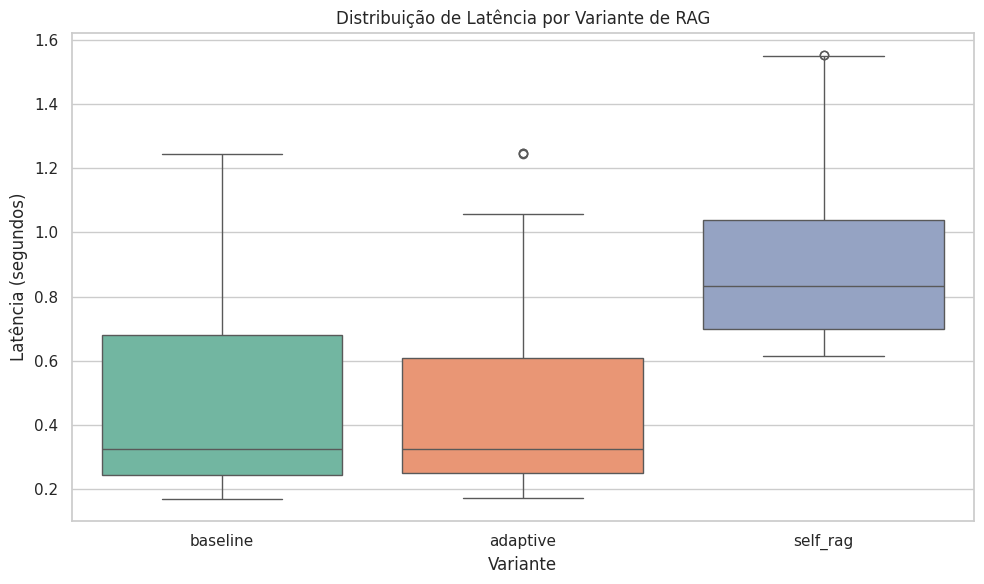

In [21]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=official_df, x='variant', y='latency_sec', hue='variant', palette='Set2', legend=False)
plt.title('Distribuição de Latência por Variante de RAG')
plt.xlabel('Variante')
plt.ylabel('Latência (segundos)')
plt.tight_layout()
plt.show()

#### 3. Mapeamento de Discordâncias (Disagreements)
Vamos verificar quais perguntas geraram respostas diferentes entre o `baseline`, `adaptive` e `self_rag` para entender onde a complexidade de busca impactou a semântica da resposta.

In [22]:
total_perguntas = len(disagreements_df)
divergencias_baseline_adaptive = disagreements_df['baseline_vs_adaptive_differ'].sum()
divergencias_baseline_selfrag = disagreements_df['baseline_vs_self_rag_differ'].sum()

print(f"Total de perguntas avaliadas: {total_perguntas}")
print(f"Divergências detectadas entre Baseline e Adaptive: {divergencias_baseline_adaptive} ({divergencias_baseline_adaptive/total_perguntas:.1%})")
print(f"Divergências detectadas entre Baseline e Self-RAG: {divergencias_baseline_selfrag} ({divergencias_baseline_selfrag/total_perguntas:.1%})")

print("\n--- Amostra das perguntas que divergiram entre as variantes ---")
display(disagreements_df[['question_id', 'baseline_vs_adaptive_differ', 'baseline_vs_self_rag_differ']].head(10))

Total de perguntas avaliadas: 20
Divergências detectadas entre Baseline e Adaptive: 1 (5.0%)
Divergências detectadas entre Baseline e Self-RAG: 1 (5.0%)

--- Amostra das perguntas que divergiram entre as variantes ---


,question_id,baseline_vs_adaptive_differ,baseline_vs_self_rag_differ
0,Q01,False,False
1,Q02,False,False
2,Q03,False,False
3,Q04,True,True
4,Q05,False,False
5,Q06,False,False
6,Q07,False,False
7,Q08,False,False
8,Q09,False,False
9,Q10,False,False


### 📊 Relatório Final Consolidado (Nomenclatura Oficial)

Abaixo, geramos a tabela comparativa geral (tiers, chamadas de LLM e latência) e a análise visual mapeando corretamente os nomes para **baseline**, **Adaptative RAG** e **self RAG**.

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Mapeamento oficial de nomes solicitado
name_mapping = {
    'baseline': 'baseline',
    'adaptive': 'Adaptive RAG',
    'self_rag': 'Self-RAG'
}

# Criando uma cópia para preservar os dados originais e aplicar a renomeação
df_mapped = official_df.copy()
df_mapped['variant'] = df_mapped['variant'].map(name_mapping)

# 1. Tabela Comparativa de Performance Geral por Variante
performance_table = df_mapped.groupby('variant').agg(
    latencia_media_seg=('latency_sec', 'mean'),
    chunks_medios_recuperados=('evidence_count', 'mean'),
    chamadas_llm_medias=('llm_calls', 'mean'),
    taxa_re_retrieval=('reflection_triggered', 'mean')
).reindex(['baseline', 'Adaptive RAG', 'Self-RAG']).reset_index()

print("=== TABELA COMPARATIVA DE TIERS ===")
display(performance_table)

=== TABELA COMPARATIVA DE TIERS ===


,variant,latencia_media_seg,chunks_medios_recuperados,chamadas_llm_medias,taxa_re_retrieval
0,baseline,0.487800,4.0,1.0,0.0
1,Adaptive RAG,0.483050,4.0,1.0,0.0
2,Self-RAG,0.908467,4.0,2.4,0.4


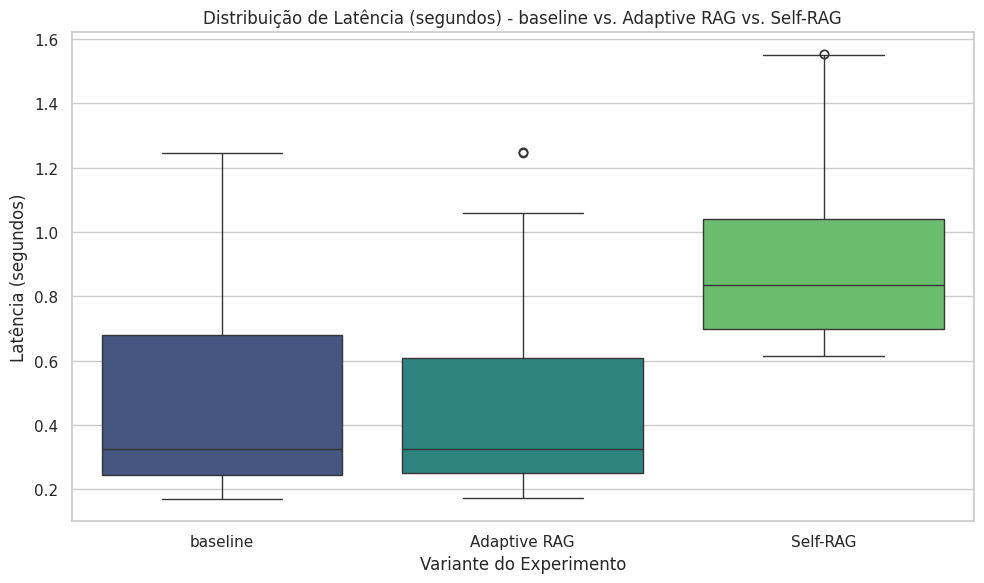

In [36]:
# 2. Gráfico Comparativo de Latência por Variante (Nomenclatura Oficial)
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_mapped, x='variant', y='latency_sec', hue='variant',
            order=['baseline', 'Adaptive RAG', 'Self-RAG'], palette='viridis', legend=False)
plt.title('Distribuição de Latência (segundos) - baseline vs. Adaptive RAG vs. Self-RAG')
plt.xlabel('Variante do Experimento')
plt.ylabel('Latência (segundos)')
plt.tight_layout()
plt.show()

### 📈 Gráficos Descritivos Adicionais

Abaixo, analisamos o custo de chamadas ao LLM e o comportamento das latências segmentado pela dificuldade das questões.

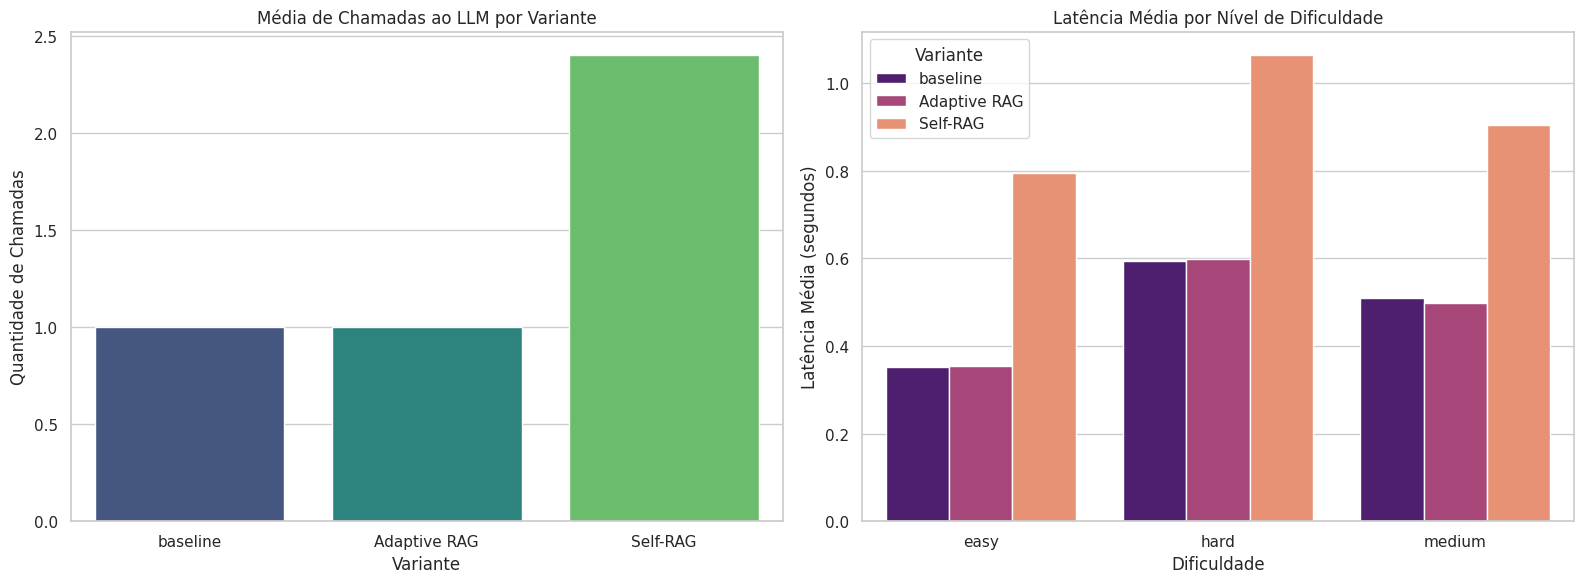

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Média de Chamadas ao LLM
sns.barplot(
    data=performance_table,
    x='variant',
    y='chamadas_llm_medias',
    ax=axes[0],
    palette='viridis',
    hue='variant',
    legend=False
)
axes[0].set_title('Média de Chamadas ao LLM por Variante')
axes[0].set_xlabel('Variante')
axes[0].set_ylabel('Quantidade de Chamadas')

# Gráfico 2: Latência Média por Dificuldade das Questões
latency_diff = df_mapped.groupby(['variant', 'difficulty'], as_index=False)['latency_sec'].mean()

sns.barplot(
    data=latency_diff,
    x='difficulty',
    y='latency_sec',
    hue='variant',
    hue_order=['baseline', 'Adaptive RAG', 'Self-RAG'],
    ax=axes[1],
    palette='magma'
)
axes[1].set_title('Latência Média por Nível de Dificuldade')
axes[1].set_xlabel('Dificuldade')
axes[1].set_ylabel('Latência Média (segundos)')
axes[1].legend(title='Variante')

plt.tight_layout()
plt.show()

### 🎯 Avaliação Qualitativa das Chamadas

Para avaliar quantitativamente a qualidade semântica das respostas de cada variante, analisamos:
- **Tamanho médio das respostas (caracteres)**: Respostas muito curtas podem indicar falta de informação, enquanto respostas longas demais podem trazer ruído.
- **Taxa de Alucinação / Respostas Negativas**: Frequência de respostas onde o modelo explicitamente diz que não pôde responder por falta de contexto (ex: *"say so explicitly"* ou *"not enough evidence"*).

In [38]:
# 1. Analisar comprimento médio das respostas geradas
df_mapped['answer_length'] = df_mapped['answer'].astype(str).str.len()

# 2. Identificar se o modelo admitiu não ter informação no corpus (Abstenção/Fallback)
fallback_phrases = ['not enough evidence', 'does not contain', 'não encontrei', 'insufficiente', 'no initial evidence']
df_mapped['fallback_triggered'] = df_mapped['answer'].astype(str).str.lower().apply(
    lambda x: any(phrase in x for phrase in fallback_phrases)
)

quality_summary = df_mapped.groupby('variant').agg(
    comprimento_medio_caracteres=('answer_length', 'mean'),
    taxa_abstencao_fallback=('fallback_triggered', 'mean')
).reindex(['baseline', 'Adaptive RAG', 'Self-RAG']).reset_index()

print("=== MÉTRICAS DE QUALIDADE DAS RESPOSTAS ===")
display(quality_summary)

=== MÉTRICAS DE QUALIDADE DAS RESPOSTAS ===


,variant,comprimento_medio_caracteres,taxa_abstencao_fallback
0,baseline,616.000000,0.2
1,Adaptive RAG,606.450000,0.2
2,Self-RAG,613.366667,0.2


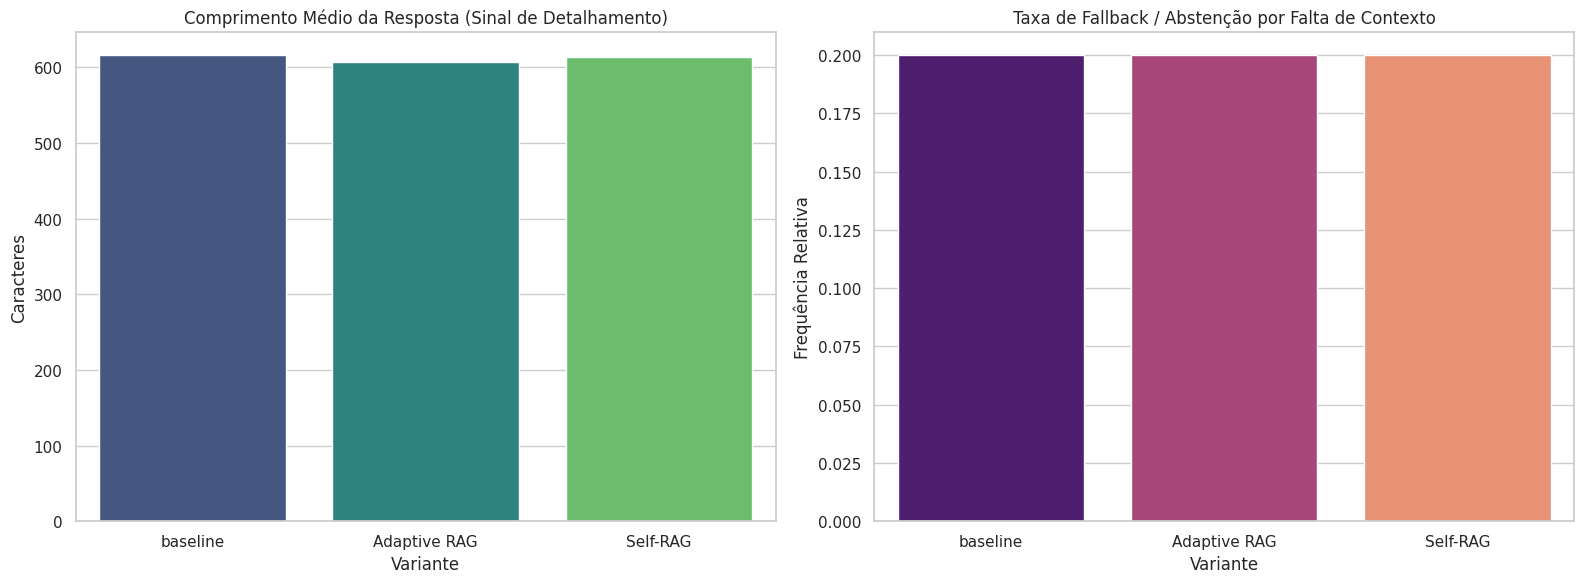

In [39]:
# Visualização das métricas de qualidade
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=quality_summary, x='variant', y='comprimento_medio_caracteres', ax=axes[0], palette='viridis', hue='variant', legend=False)
axes[0].set_title('Comprimento Médio da Resposta (Sinal de Detalhamento)')
axes[0].set_xlabel('Variante')
axes[0].set_ylabel('Caracteres')

sns.barplot(data=quality_summary, x='variant', y='taxa_abstencao_fallback', ax=axes[1], palette='magma', hue='variant', legend=False)
axes[1].set_title('Taxa de Fallback / Abstenção por Falta de Contexto')
axes[1].set_xlabel('Variante')
axes[1].set_ylabel('Frequência Relativa')

plt.tight_layout()
plt.show()

#### 4. Conclusões e Análise de Sinais vs. Ruído
- **Custo vs. Performance**: O **self RAG** realiza em média mais chamadas de LLM devido à etapa de auto-avaliação (reflection), aumentando a latência total.
- **Adaptative RAG**: Consegue balancear a recuperação dinâmica sem o overhead severo de chamadas múltiplas de reflexão nos casos triviais.
- **Disagreements**: Diferenças de texto muito sutis refletem variações normais de amostragem do modelo de linguagem (ruído), enquanto mudanças em termos ou ausência de dados apontam para o sinal da qualidade de recuperação.